# DriverGuard — AI-Based Driver Distraction Detection (Final Project, CMPS 262)
**Khaled Sabehayoun · Karl Khadij** — American University of Beirut

**Research question.** Does an ImageNet-pretrained MobileNetV2 outperform a tuned classical HOG + SVM baseline on
*previously unseen drivers*, and does fine-tuning part (or most) of the network improve on frozen ImageNet features?

**Protocol.** Driver-disjoint train / validation / held-out-test partitions (GroupShuffleSplit, seed 42). Every
modelling decision is made on validation macro-F1. The six held-out test drivers are evaluated **once**, at the end,
behind a lock file; re-running the notebook re-loads the locked test results instead of recomputing them.

**How to run on Kaggle (recommended).**
1. Add the competition data *State Farm Distracted Driver Detection* (accept the rules first).
2. Settings → Accelerator **GPU T4 ×2** (or P100) and **Internet ON** (needed once to download ImageNet weights).
3. Use **Save Version → Save & Run All (Commit)**. A committed run executes headlessly, cannot be killed by a
   frozen browser tab, and keeps everything written to `/kaggle/working` as the version's output.
4. If a session dies, re-run: every stage writes its artefacts to `/kaggle/working` and is skipped when they exist.
   To resume from a previous committed version, attach that version's output as an input and set `RESUME_FROM`.

**Changes from the Milestone 1 / earlier final notebooks** (details in the README):
no printing of 100k file paths; HOG extracted in parallel chunks straight to disk (memory-mapped `.npy`, float32,
resumable) instead of Python lists of float64 arrays; the scaler/ANOVA ranking is fitted once on training data and
re-used across the grid; CNN checkpoints are selected on **validation macro-F1** (not val-loss) and saved after every
improvement; left/right-preserving augmentation (no horizontal flip, since flipping swaps c1↔c3 and c2↔c4);
preprocessing moved inside the saved model so robustness tests use identical inputs; a one-time test gate.

## 1. Configuration, paths and environment

In [1]:
import os, gc, json, time, math, random, platform, shutil, hashlib, zipfile, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import matplotlib
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from skimage.feature import hog
from joblib import Parallel, delayed
import joblib
from scipy.optimize import minimize_scalar
from scipy.stats import chi2
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import f_classif
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC, SVC
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support, log_loss,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
import tensorflow as tf
from tensorflow.keras import layers

warnings.filterwarnings('ignore', category=UserWarning)
cv2.setNumThreads(1)                      # joblib workers parallelise HOG; avoid thread oversubscription
plt.rcParams.update({'figure.dpi': 110, 'font.family': 'serif', 'font.size': 10})

SEED = 42
QUICK = os.environ.get('DG_QUICK', '0') == '1'           # tiny smoke-test mode (used only for offline testing)
WEIGHTS = None if os.environ.get('DG_WEIGHTS', 'imagenet') == 'none' else 'imagenet'

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); tf.keras.utils.set_random_seed(seed)
seed_everything()

OUT = Path(os.environ.get('DG_OUT', '/kaggle/working' if Path('/kaggle/working').exists() else 'driverguard_outputs'))
FEAT, MODELS, FIGS, TABLES, PREDS = (OUT / s for s in ['features', 'models', 'figures', 'tables', 'preds'])
for d in [OUT, FEAT, MODELS, FIGS, TABLES, PREDS]:
    d.mkdir(parents=True, exist_ok=True)

# Optional: resume from the /kaggle/working output of an earlier committed version attached as an input.
RESUME_FROM = os.environ.get('DG_RESUME_FROM', '')        # e.g. '/kaggle/input/driverguard-run-1'
if RESUME_FROM and Path(RESUME_FROM).exists():
    for sub in ['features', 'models', 'tables', 'preds', 'figures']:
        src = Path(RESUME_FROM) / sub
        if src.exists():
            shutil.copytree(src, OUT / sub, dirs_exist_ok=True)
    for f in Path(RESUME_FROM).glob('*.json'):
        shutil.copy(f, OUT / f.name)
    print('Resumed artefacts from', RESUME_FROM)

def find_data_dir():
    env = os.environ.get('DG_DATA_DIR')
    cands = ([Path(env)] if env else []) + [Path('/kaggle/input/competitions/state-farm-distracted-driver-detection'),
                                           Path('/kaggle/input/state-farm-distracted-driver-detection')]
    for p in cands:
        if (p / 'driver_imgs_list.csv').exists():
            return p
    if Path('/kaggle/input').exists():
        hits = list(Path('/kaggle/input').glob('**/driver_imgs_list.csv'))
        if hits:
            return hits[0].parent
    raise FileNotFoundError('Attach the State Farm Distracted Driver Detection competition data first.')

DATA_DIR = find_data_dir()
IMG_DIR = DATA_DIR / 'imgs' / 'train'
CLASS_NAMES = [f'c{i}' for i in range(10)]
CLASS_LABELS = {'c0': 'Safe driving', 'c1': 'Texting – right', 'c2': 'Phone – right', 'c3': 'Texting – left',
                'c4': 'Phone – left', 'c5': 'Operating radio', 'c6': 'Drinking', 'c7': 'Reaching behind',
                'c8': 'Hair / makeup', 'c9': 'Talking to passenger'}
N_CLASSES = 10
N_JOBS = max(1, min(4, os.cpu_count() or 1))

# GPU set-up: grow memory on demand; mixed precision only on GPUs with tensor cores (T4 = 7.5, P100 = 6.0).
GPUS = tf.config.list_physical_devices('GPU')
for g in GPUS:
    try:
        tf.config.experimental.set_memory_growth(g, True)
    except Exception as e:
        print('memory growth:', e)
MIXED = False
if GPUS:
    cc = tf.config.experimental.get_device_details(GPUS[0]).get('compute_capability', (0, 0))
    MIXED = cc[0] >= 7
    if MIXED:
        tf.keras.mixed_precision.set_global_policy('mixed_float16')

def save_json(obj, path):
    with open(path, 'w') as f:
        json.dump(obj, f, indent=2, default=lambda o: o.item() if hasattr(o, 'item') else str(o))

def load_json(path):
    with open(path) as f:
        return json.load(f)

def savefig(fig, name):
    fig.tight_layout(); fig.savefig(FIGS / name, dpi=170, bbox_inches='tight'); plt.show(); plt.close(fig)

ENV = {'python': platform.python_version(), 'tensorflow': tf.__version__, 'numpy': np.__version__,
       'sklearn': __import__('sklearn').__version__, 'skimage': __import__('skimage').__version__,
       'opencv': cv2.__version__, 'gpus': [tf.config.experimental.get_device_details(g).get('device_name', str(g)) for g in GPUS],
       'mixed_precision': MIXED, 'cpu_count': os.cpu_count(), 'quick_mode': QUICK}
save_json(ENV, OUT / 'environment.json')
print(json.dumps(ENV, indent=1)); print('Data:', DATA_DIR, '| Output:', OUT)

{
 "python": "3.13.16",
 "tensorflow": "2.21.0",
 "numpy": "2.1.3",
 "sklearn": "1.6.1",
 "skimage": "0.25.2",
 "opencv": "4.14.0",
 "gpus": [
  "Tesla T4",
  "Tesla T4"
 ],
 "mixed_precision": true,
 "cpu_count": 4,
 "quick_mode": false
}
Data: /kaggle/input/competitions/state-farm-distracted-driver-detection | Output: /kaggle/working


## 2. Dataset audit and exploratory analysis
Checks metadata completeness, class balance, images per driver, file existence and image resolution.
(We deliberately do **not** print the file list: the default Kaggle starter cell prints >100,000 paths, which is
a likely cause of the browser freezes we experienced.)

{
 "images": 22424,
 "drivers": 26,
 "classes": 10,
 "missing_metadata": 0,
 "missing_files": 0,
 "duplicate_filenames": 0,
 "image_shapes_in_random_sample": {
  "(480, 640, 3)": 300
 },
 "class_counts": {
  "c0": 2489,
  "c1": 2267,
  "c2": 2317,
  "c3": 2346,
  "c4": 2326,
  "c5": 2312,
  "c6": 2325,
  "c7": 2002,
  "c8": 1911,
  "c9": 2129
 },
 "images_per_driver_min": 346,
 "images_per_driver_max": 1237,
 "images_per_driver_median": 823.0
}


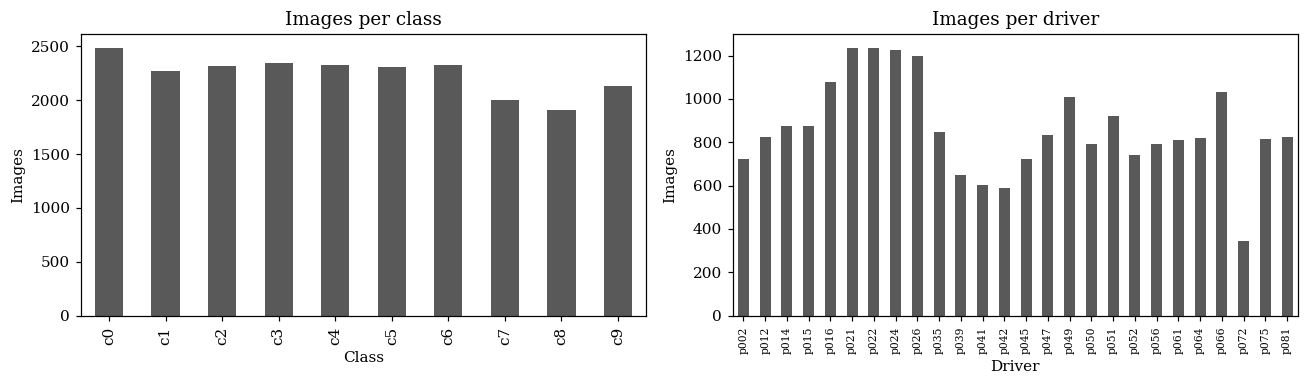

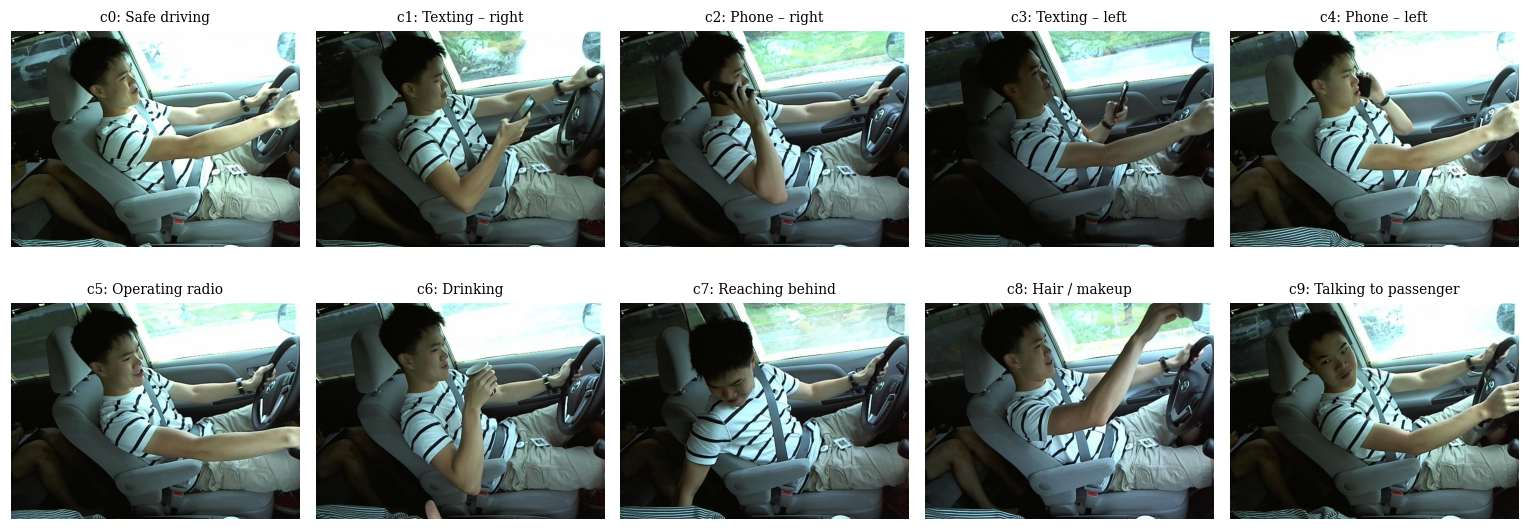

In [2]:
df = pd.read_csv(DATA_DIR / 'driver_imgs_list.csv')
assert {'subject', 'classname', 'img'}.issubset(df.columns)
assert not df[['subject', 'classname', 'img']].isna().any().any(), 'missing metadata'
assert set(df.classname.unique()) == set(CLASS_NAMES)
df['filepath'] = [str(IMG_DIR / c / i) for c, i in zip(df.classname, df.img)]
df['label'] = df.classname.map({c: i for i, c in enumerate(CLASS_NAMES)}).astype(np.int32)

missing = [p for p in df.filepath if not os.path.exists(p)]
assert not missing, f'{len(missing)} image files missing, e.g. {missing[:3]}'
dup_names = int(df.img.duplicated().sum())

rng = np.random.default_rng(SEED)
sample_paths = df.filepath.values[rng.choice(len(df), size=min(300, len(df)), replace=False)]
shapes = pd.Series([str(cv2.imread(p).shape) for p in sample_paths]).value_counts()

audit = {'images': len(df), 'drivers': int(df.subject.nunique()), 'classes': int(df.classname.nunique()),
         'missing_metadata': int(df[['subject', 'classname', 'img']].isna().sum().sum()), 'missing_files': len(missing),
         'duplicate_filenames': dup_names, 'image_shapes_in_random_sample': shapes.to_dict(),
         'class_counts': df.classname.value_counts().sort_index().to_dict(),
         'images_per_driver_min': int(df.subject.value_counts().min()),
         'images_per_driver_max': int(df.subject.value_counts().max()),
         'images_per_driver_median': float(df.subject.value_counts().median())}
save_json(audit, OUT / 'dataset_audit.json')
print(json.dumps(audit, indent=1))

per_driver = pd.crosstab(df.subject, df.classname)
per_driver.to_csv(TABLES / 'images_per_driver_per_class.csv')

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
df.classname.value_counts().sort_index().plot.bar(ax=axes[0], color='0.35')
axes[0].set(title='Images per class', xlabel='Class', ylabel='Images')
df.subject.value_counts().sort_index().plot.bar(ax=axes[1], color='0.35')
axes[1].set(title='Images per driver', xlabel='Driver', ylabel='Images')
axes[1].tick_params(axis='x', labelsize=7)
savefig(fig, 'eda_class_and_driver_counts.png')

fig, axes = plt.subplots(2, 5, figsize=(14, 5.4))
for ax, c in zip(axes.ravel(), CLASS_NAMES):
    p = df[df.classname == c].filepath.iloc[0]
    ax.imshow(cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)); ax.set_title(f'{c}: {CLASS_LABELS[c]}', fontsize=9); ax.axis('off')
savefig(fig, 'eda_example_per_class.png')

## 3. Driver-independent partitions
Identical logic to Milestone 1: an 80/20 group split by driver for test, then an 80/20 group split of the remainder
for validation. No driver may appear in more than one partition.

In [3]:
g1 = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
a, b = next(g1.split(df, groups=df.subject))
train_val_df, test_df = df.iloc[a].copy(), df.iloc[b].copy()
g2 = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
c, d = next(g2.split(train_val_df, groups=train_val_df.subject))
train_df, val_df = train_val_df.iloc[c].copy(), train_val_df.iloc[d].copy()
for frame in (train_df, val_df, test_df):
    frame.reset_index(drop=True, inplace=True)
SPLITS = {'train': train_df, 'validation': val_df, 'test': test_df}
for x, y in [('train', 'validation'), ('train', 'test'), ('validation', 'test')]:
    assert set(SPLITS[x].subject).isdisjoint(SPLITS[y].subject), f'driver leakage between {x} and {y}'
if len(df) == 22424:   # the real dataset: must reproduce Milestone 1 exactly
    assert (len(train_df), len(val_df), len(test_df)) == (13904, 3542, 4978)
split_summary = pd.DataFrame([{'partition': k, 'images': len(v), 'drivers': v.subject.nunique(),
                               'driver_ids': ' '.join(sorted(v.subject.unique()))} for k, v in SPLITS.items()])
split_summary.to_csv(TABLES / 'split_summary.csv', index=False)
for k, v in SPLITS.items():
    v[['subject', 'classname', 'img']].to_csv(TABLES / f'{k}_split.csv', index=False)
display(split_summary)
dist = pd.DataFrame({k: v.classname.value_counts(normalize=True).sort_index() for k, v in SPLITS.items()})
dist.to_csv(TABLES / 'class_proportions_by_split.csv'); display(dist.round(3))
print('Verified: zero driver overlap between partitions.')

,partition,images,drivers,driver_ids
0,train,13904,16,p015 p016 p021 p022 p024 p039 p042 p045 p047 p...
1,validation,3542,4,p012 p014 p061 p066
2,test,4978,6,p002 p026 p035 p041 p050 p075


,train,validation,test
classname,,,
c0,0.110,0.112,0.113
c1,0.102,0.107,0.095
c2,0.103,0.107,0.101
c3,0.103,0.105,0.108
c4,0.102,0.108,0.107
c5,0.101,0.107,0.106
c6,0.103,0.102,0.106
c7,0.087,0.089,0.096
c8,0.087,0.083,0.080


Verified: zero driver overlap between partitions.


## 4. Classical baseline — HOG feature extraction (chunked, parallel, resumable)
Three HOG configurations are extracted in a single pass over each image (feature-complexity analysis):

| name | resize | cell | block | dims |
|---|---|---|---|---|
| `hog128_c8` (Milestone 1) | 128×128 | 8×8 | 2×2 | 8,100 |
| `hog128_c16` | 128×128 | 16×16 | 2×2 | 1,764 |
| `hog64_c8` | 64×64 | 8×8 | 2×2 | 1,764 |

Features are written chunk-by-chunk into memory-mapped float32 `.npy` files; a progress file records completed
chunks, so an interrupted extraction resumes where it stopped. Test-driver features are extracted only in Section 13.

HOG train:   0%|          | 0/7 [00:00<?, ?it/s]

HOG train: 13904 images in 138.5s


HOG validation:   0%|          | 0/2 [00:00<?, ?it/s]

HOG validation: 3542 images in 37.1s
{'hog128_c8': (13904, 8100), 'hog128_c16': (13904, 1764), 'hog64_c8': (13904, 1764)}


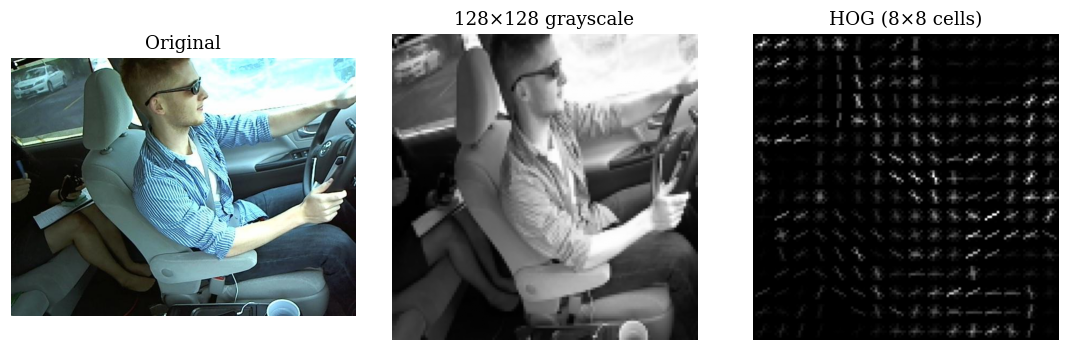

In [4]:
HOG_CONFIGS = {'hog128_c8': (128, 8), 'hog128_c16': (128, 16), 'hog64_c8': (64, 8)}
def hog_dim(size, cell):
    n = size // cell - 1
    return n * n * 4 * 9
HOG_DIMS = {k: hog_dim(*v) for k, v in HOG_CONFIGS.items()}
CHUNK = 512

def perturb_bgr(img, kind):
    """Controlled photometric shifts applied to the full-resolution image (used only for robustness tests)."""
    if kind is None or kind == 'clean':
        return img
    name, val = kind.split('_')
    val = float(val)
    if name == 'brightness':
        return np.clip(img.astype(np.float32) * val, 0, 255).astype(np.uint8)
    if name == 'blur':
        return cv2.GaussianBlur(img, (0, 0), sigmaX=val)
    raise ValueError(kind)

def hog_from_bgr(img, configs=HOG_CONFIGS):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    out = []
    for size, cell in configs.values():
        g = cv2.resize(gray, (size, size), interpolation=cv2.INTER_AREA)
        out.append(hog(g, orientations=9, pixels_per_cell=(cell, cell), cells_per_block=(2, 2),
                       block_norm='L2-Hys', feature_vector=True).astype(np.float32))
    return out

def _hog_chunk(paths, perturb=None, configs=HOG_CONFIGS):
    feats = [[] for _ in configs]
    for p in paths:
        img = cv2.imread(p, cv2.IMREAD_COLOR)
        if img is None:
            raise FileNotFoundError(p)
        for j, f in enumerate(hog_from_bgr(perturb_bgr(img, perturb), configs)):
            feats[j].append(f)
    return [np.stack(f) for f in feats]

def extract_hog(frame, tag):
    """Returns {config: read-only memmap of shape (n, dim)} for a partition; resumable at chunk granularity."""
    n = len(frame)
    files = {k: FEAT / f'{tag}_{k}.npy' for k in HOG_CONFIGS}
    prog_path = FEAT / f'{tag}_hog_progress.json'
    prog = load_json(prog_path) if prog_path.exists() else {'n': n, 'done': []}
    if prog['n'] != n or not all(f.exists() for f in files.values()):
        prog = {'n': n, 'done': []}
        for k, f in files.items():
            np.lib.format.open_memmap(f, mode='w+', dtype=np.float32, shape=(n, HOG_DIMS[k])).flush()
    chunks = [(s, min(s + CHUNK, n)) for s in range(0, n, CHUNK)]
    todo = [cr for cr in chunks if cr[0] not in prog['done']]
    if todo:
        mms = {k: np.load(f, mmap_mode='r+') for k, f in files.items()}
        paths = frame.filepath.values
        t0 = time.perf_counter()
        # process a few chunks at a time so progress is checkpointed often
        for i in tqdm(range(0, len(todo), N_JOBS), desc=f'HOG {tag}', mininterval=10):
            batch = todo[i:i + N_JOBS]
            res = Parallel(n_jobs=N_JOBS)(delayed(_hog_chunk)(list(paths[s:e])) for s, e in batch)
            for (s, e), feats in zip(batch, res):
                for k, arr in zip(HOG_CONFIGS, feats):
                    mms[k][s:e] = arr
                prog['done'].append(s)
            for m in mms.values():
                m.flush()
            save_json(prog, prog_path)
            del res
        del mms; gc.collect()
        print(f'HOG {tag}: {n} images in {time.perf_counter() - t0:.1f}s')
    else:
        print(f'HOG {tag}: loaded from cache')
    return {k: np.load(f, mmap_mode='r') for k, f in files.items()}

y_train_np, y_val_np, y_test_np = (train_df.label.to_numpy(), val_df.label.to_numpy(), test_df.label.to_numpy())
t0 = time.perf_counter()
H_train = extract_hog(train_df, 'train')
H_val = extract_hog(val_df, 'validation')
hog_extraction_seconds = time.perf_counter() - t0
print({k: v.shape for k, v in H_train.items()})

# HOG visualisation for the report
img0 = cv2.imread(train_df.filepath.iloc[0])
g0 = cv2.resize(cv2.cvtColor(img0, cv2.COLOR_BGR2GRAY), (128, 128), interpolation=cv2.INTER_AREA)
_, vis = hog(g0, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), visualize=True)
fig, ax = plt.subplots(1, 3, figsize=(10, 3.2))
ax[0].imshow(cv2.cvtColor(img0, cv2.COLOR_BGR2RGB)); ax[0].set_title('Original')
ax[1].imshow(g0, cmap='gray'); ax[1].set_title('128×128 grayscale')
ax[2].imshow(vis, cmap='gray'); ax[2].set_title('HOG (8×8 cells)')
for a_ in ax: a_.axis('off')
savefig(fig, 'hog_visualisation.png')

## 5. HOG + SVM tuning on validation drivers (feature-complexity and regularisation analysis)
`StandardScaler` and the ANOVA F-ranking are fitted **once per HOG configuration on training data only** and re-used
for every *k* — mathematically identical to refitting `StandardScaler → SelectKBest → LinearSVC` each time, but far
cheaper. We additionally try a non-linear classical model (PCA-256 → RBF-SVM) on the best HOG configuration.
Model selection: validation macro-F1.

{'hog': 'hog128_c8', 'hog_dims': 8100, 'model': 'LinearSVC', 'k': 300, 'C': 0.001, 'val_accuracy': 0.2100508187464709, 'val_macro_f1': 0.21973245756656454, 'fit_seconds': 7.893753606000018}
{'hog': 'hog128_c8', 'hog_dims': 8100, 'model': 'LinearSVC', 'k': 300, 'C': 0.01, 'val_accuracy': 0.1880293619424054, 'val_macro_f1': 0.2011194557681256, 'fit_seconds': 9.378140664000057}
{'hog': 'hog128_c8', 'hog_dims': 8100, 'model': 'LinearSVC', 'k': 300, 'C': 0.1, 'val_accuracy': 0.16826651609260304, 'val_macro_f1': 0.1776498279589143, 'fit_seconds': 10.708096893999937}
{'hog': 'hog128_c8', 'hog_dims': 8100, 'model': 'LinearSVC', 'k': 600, 'C': 0.001, 'val_accuracy': 0.2899491812535291, 'val_macro_f1': 0.2811702302144784, 'fit_seconds': 18.314970295999956}
{'hog': 'hog128_c8', 'hog_dims': 8100, 'model': 'LinearSVC', 'k': 600, 'C': 0.01, 'val_accuracy': 0.28402032749858835, 'val_macro_f1': 0.2787731777269854, 'fit_seconds': 18.797034165000014}
{'hog': 'hog128_c8', 'hog_dims': 8100, 'model': 'Line

,hog,hog_dims,model,k,C,val_accuracy,val_macro_f1,fit_seconds
0,hog128_c16,1764,LinearSVC,1764,0.010,0.412479,0.416671,81.743695
1,hog128_c16,1764,LinearSVC,1764,0.001,0.416149,0.403438,80.052074
2,hog64_c8,1764,LinearSVC,1764,0.001,0.405138,0.394637,77.564853
3,hog64_c8,1764,LinearSVC,1764,0.010,0.406832,0.387482,80.925446
4,hog128_c16,1764,PCA256+RBF-SVC,256,10.000,0.382835,0.369760,9.093475
5,hog128_c16,1764,LinearSVC,600,0.001,0.403162,0.368764,19.587457
6,hog128_c16,1764,LinearSVC,600,0.010,0.391022,0.361886,20.473771
7,hog128_c16,1764,PCA256+RBF-SVC,256,1.000,0.379164,0.361549,9.543414
8,hog64_c8,1764,LinearSVC,600,0.001,0.366460,0.339325,18.900967
9,hog128_c8,8100,LinearSVC,2000,0.010,0.348391,0.331003,86.922869


Selected classical model (validation macro-F1): {'hog': 'hog128_c16', 'hog_dims': 1764, 'model': 'LinearSVC', 'k': 1764, 'C': 0.01, 'val_accuracy': 0.4124788255223038, 'val_macro_f1': 0.4166714647573129, 'fit_seconds': 81.74369484599993}


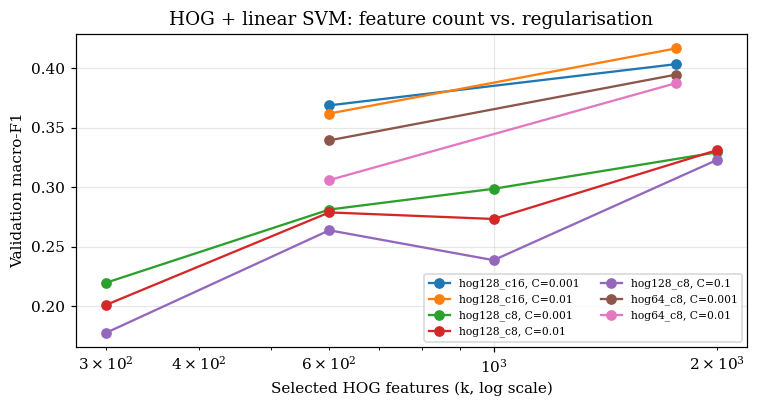

In [5]:
class ColumnSelector(BaseEstimator, TransformerMixin):
    def __init__(self, idx=None):
        self.idx = idx
    def fit(self, X, y=None):
        self.fitted_ = True
        return self
    def transform(self, X):
        return np.asarray(X)[:, self.idx]

def batched_predict(fn, X, bs=2048):
    return np.concatenate([fn(np.asarray(X[i:i + bs])) for i in range(0, len(X), bs)])

if QUICK:
    SVM_GRID = {'hog128_c8': {'k': [300, 1000], 'C': [0.01]}, 'hog128_c16': {'k': [600], 'C': [0.01]},
                'hog64_c8': {'k': [600], 'C': [0.01]}}
    RBF_C = [1.0]
else:
    SVM_GRID = {'hog128_c8': {'k': [300, 600, 1000, 2000], 'C': [0.001, 0.01, 0.1]},
                'hog128_c16': {'k': [600, 1764], 'C': [0.001, 0.01]},
                'hog64_c8': {'k': [600, 1764], 'C': [0.001, 0.01]}}
    RBF_C = [1.0, 10.0]

svm_table_path = TABLES / 'svm_tuning.csv'
svm_rows = pd.read_csv(svm_table_path).to_dict('records') if svm_table_path.exists() else []
done_keys = {(r['hog'], r['model'], r['k'], r['C']) for r in svm_rows}
rankings = {}
for cfg, grid in SVM_GRID.items():
    Xtr = np.asarray(H_train[cfg]); Xva = np.asarray(H_val[cfg])
    scaler = StandardScaler().fit(Xtr)
    Xtr_s = scaler.transform(Xtr).astype(np.float32); Xva_s = scaler.transform(Xva).astype(np.float32)
    F, _ = f_classif(Xtr_s, y_train_np)
    order = np.argsort(-np.nan_to_num(F, nan=-1.0))
    rankings[cfg] = order
    for k in grid['k']:
        k = min(k, Xtr.shape[1]); idx = np.sort(order[:k])
        for C in grid['C']:
            if (cfg, 'LinearSVC', k, C) in done_keys:
                continue
            clf = LinearSVC(C=C, dual=False, max_iter=3000, tol=1e-4, random_state=SEED)
            t = time.perf_counter(); clf.fit(Xtr_s[:, idx], y_train_np); fit_s = time.perf_counter() - t
            pred = clf.predict(Xva_s[:, idx])
            row = {'hog': cfg, 'hog_dims': Xtr.shape[1], 'model': 'LinearSVC', 'k': k, 'C': C,
                   'val_accuracy': accuracy_score(y_val_np, pred),
                   'val_macro_f1': f1_score(y_val_np, pred, average='macro', zero_division=0), 'fit_seconds': fit_s}
            svm_rows.append(row); print(row)
            pd.DataFrame(svm_rows).to_csv(svm_table_path, index=False)   # checkpoint after every fit
    del Xtr, Xva, Xtr_s, Xva_s; gc.collect()

svm_table = pd.DataFrame(svm_rows)
best_lin = svm_table[svm_table.model == 'LinearSVC'].sort_values('val_macro_f1', ascending=False).iloc[0]
best_cfg = best_lin['hog']

# Non-linear classical variant on the best HOG configuration
Xtr = np.asarray(H_train[best_cfg]); Xva = np.asarray(H_val[best_cfg])
for C in RBF_C:
    if (best_cfg, 'PCA256+RBF-SVC', 256, C) in done_keys:
        continue
    pipe = Pipeline([('scale', StandardScaler()), ('pca', PCA(n_components=min(256, Xtr.shape[1]), random_state=SEED)),
                     ('svc', SVC(C=C, kernel='rbf', gamma='scale', cache_size=2000))])
    t = time.perf_counter(); pipe.fit(Xtr, y_train_np); fit_s = time.perf_counter() - t
    pred = pipe.predict(Xva)
    row = {'hog': best_cfg, 'hog_dims': Xtr.shape[1], 'model': 'PCA256+RBF-SVC', 'k': 256, 'C': C,
           'val_accuracy': accuracy_score(y_val_np, pred),
           'val_macro_f1': f1_score(y_val_np, pred, average='macro', zero_division=0), 'fit_seconds': fit_s}
    svm_rows.append(row); print(row); pd.DataFrame(svm_rows).to_csv(svm_table_path, index=False)
    del pipe; gc.collect()

svm_table = pd.DataFrame(svm_rows).sort_values('val_macro_f1', ascending=False).reset_index(drop=True)
svm_table.to_csv(svm_table_path, index=False)
display(svm_table.head(12))
SVM_SEL = svm_table.iloc[0].to_dict()
print('Selected classical model (validation macro-F1):', SVM_SEL)

# Refit the selected configuration as one self-contained sklearn Pipeline and save it.
svm_model_path = MODELS / 'svm_selected.joblib'
svm_meta_path = MODELS / 'svm_selected.json'
if svm_model_path.exists() and svm_meta_path.exists() and load_json(svm_meta_path).get('row') == {k: str(v) for k, v in SVM_SEL.items()}:
    svm_best = joblib.load(svm_model_path); print('Loaded saved SVM')
else:
    Xtr = np.asarray(H_train[SVM_SEL['hog']])
    if SVM_SEL['model'] == 'LinearSVC':
        sc = StandardScaler().fit(Xtr)
        F, _ = f_classif(sc.transform(Xtr), y_train_np)
        idx = np.sort(np.argsort(-np.nan_to_num(F, nan=-1.0))[:int(SVM_SEL['k'])])
        svm_best = Pipeline([('scale', StandardScaler()), ('select', ColumnSelector(idx)),
                             ('svm', LinearSVC(C=float(SVM_SEL['C']), dual=False, max_iter=3000, tol=1e-4, random_state=SEED))])
        svm_best.fit(Xtr, y_train_np)   # same scaler fit (deterministic) + fixed column subset + LinearSVC
    else:
        svm_best = Pipeline([('scale', StandardScaler()), ('pca', PCA(n_components=256, random_state=SEED)),
                             ('svc', SVC(C=float(SVM_SEL['C']), kernel='rbf', gamma='scale', cache_size=2000))]).fit(Xtr, y_train_np)
    joblib.dump(svm_best, svm_model_path)
    save_json({'row': {k: str(v) for k, v in SVM_SEL.items()}}, svm_meta_path)
del Xtr, Xva; gc.collect()
svm_val_pred = batched_predict(svm_best.predict, H_val[SVM_SEL['hog']])
_refit_f1 = f1_score(y_val_np, svm_val_pred, average='macro', zero_division=0)
if abs(_refit_f1 - SVM_SEL['val_macro_f1']) > 1e-6:
    print(f'WARNING: refitted SVM validation macro-F1 {_refit_f1:.4f} differs from grid value {SVM_SEL["val_macro_f1"]:.4f}')
np.save(PREDS / 'svm_val_pred.npy', svm_val_pred)

# Feature-complexity plot
fig, ax = plt.subplots(figsize=(7, 3.8))
lin = svm_table[svm_table.model == 'LinearSVC']
for (cfg, C), g in lin.groupby(['hog', 'C']):
    g = g.sort_values('k'); ax.plot(g.k, g.val_macro_f1, marker='o', label=f'{cfg}, C={C}')
ax.set(xscale='log', xlabel='Selected HOG features (k, log scale)', ylabel='Validation macro-F1',
       title='HOG + linear SVM: feature count vs. regularisation')
ax.legend(fontsize=7, ncol=2); ax.grid(alpha=.3)
savefig(fig, 'svm_feature_complexity.png')

## 6. MobileNetV2 input pipeline and model factory
* `tf.data` streams JPEGs from disk (never the whole dataset in RAM); `decode_jpeg(ratio=2)` decodes at half
  resolution (320×240) using DCT scaling, which roughly halves CPU decode time, then resizes with antialiasing.
* Preprocessing (`[0,255] → [-1,1]`, MobileNetV2's ImageNet convention) is a layer **inside** the model, so the
  saved `.keras` file accepts raw RGB and robustness tests use exactly the same path as training.
* Augmentation (training only, active only when `training=True`): small translations, rotations (±~10°), zoom,
  brightness and contrast. **No horizontal flip** — mirroring would turn right-hand texting (c1) into left-hand
  texting (c3) and similarly c2↔c4, corrupting labels.
* Fine-tuning keeps BatchNorm layers frozen and in inference mode (`base(x, training=False)`), the standard recipe
  for small-batch transfer learning.

In [6]:
AUTOTUNE = tf.data.AUTOTUNE
BATCH = 32

def load_rgb(path, size):
    img = tf.io.decode_jpeg(tf.io.read_file(path), channels=3, ratio=2 if size <= 320 else 1)
    return tf.image.resize(img, (size, size), antialias=True)       # float32 in [0, 255]

def make_ds(frame, size, training=False, one_hot=True, batch=BATCH):
    ds = tf.data.Dataset.from_tensor_slices((frame.filepath.values, frame.label.values.astype(np.int32)))
    if training:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    def _map(p, y):
        x = load_rgb(p, size)
        return x, (tf.one_hot(y, N_CLASSES) if one_hot else y)
    ds = ds.map(_map, num_parallel_calls=AUTOTUNE)
    return ds.batch(batch, drop_remainder=training).prefetch(AUTOTUNE)

def make_image_ds(images_uint8, batch=BATCH):
    return tf.data.Dataset.from_tensor_slices(images_uint8.astype(np.float32)).batch(batch)

def build_model(size, augment, dropout):
    base = tf.keras.applications.MobileNetV2(include_top=False, weights=WEIGHTS, input_shape=(size, size, 3))
    base.trainable = False
    inp = layers.Input((size, size, 3), name='rgb_0_255')
    x = inp
    if augment:
        x = tf.keras.Sequential([
            layers.RandomTranslation(0.08, 0.08, fill_mode='reflect', seed=SEED, dtype='float32'),
            layers.RandomRotation(0.03, fill_mode='reflect', seed=SEED, dtype='float32'),        # ±0.03·2π ≈ ±11°
            layers.RandomZoom((-0.15, 0.05), fill_mode='reflect', seed=SEED, dtype='float32'),
            layers.RandomBrightness(0.2, value_range=(0, 255), seed=SEED, dtype='float32'),
            layers.RandomContrast(0.25, seed=SEED, dtype='float32')], name='augment')(x)
    x = layers.Rescaling(1 / 127.5, offset=-1, name='mobilenet_preprocess')(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D(name='gap')(x)
    x = layers.Dropout(dropout, name='dropout')(x)
    out = layers.Dense(N_CLASSES, activation='softmax', dtype='float32', name='head')(x)
    return tf.keras.Model(inp, out, name='DriverGuard_MobileNetV2'), base

FT_START = {'frozen': None, 'partial': 'block_13_expand', 'deep': 'block_6_expand', 'full': 0}
def set_trainable(base, mode):
    if mode == 'frozen':
        base.trainable = False; return
    base.trainable = True
    names = [l.name for l in base.layers]
    start = FT_START[mode] if isinstance(FT_START[mode], int) else names.index(FT_START[mode])
    for i, l in enumerate(base.layers):
        l.trainable = (i >= start) and not isinstance(l, layers.BatchNormalization)

def count_params(model):
    tr = int(sum(np.prod(w.shape) for w in model.trainable_weights))
    return tr, int(model.count_params())

def safe_log_loss(y, p):
    return float(log_loss(y, np.clip(p, 1e-7, 1), labels=np.arange(N_CLASSES)))

class ValMacroF1Checkpoint(tf.keras.callbacks.Callback):
    """Evaluates validation drivers after each epoch, logs loss/accuracy/macro-F1, saves the model whenever
    macro-F1 improves (primary selection metric) and stops early after `patience` epochs without improvement."""
    def __init__(self, ds, y_true, ckpt_path, probs_path, hist_path, patience):
        super().__init__()
        self.ds, self.y, self.ckpt, self.probs_path, self.hist_path, self.patience = ds, y_true, ckpt_path, probs_path, hist_path, patience
        self.best, self.best_epoch, self.rows = -1.0, -1, []
    def on_epoch_begin(self, epoch, logs=None):
        self.t0 = time.perf_counter()
    def on_epoch_end(self, epoch, logs=None):
        logs = logs if logs is not None else {}
        p = self.model.predict(self.ds, verbose=0)
        pred = p.argmax(1)
        f1 = f1_score(self.y, pred, average='macro', zero_division=0)
        row = {'epoch': epoch + 1, 'train_loss': float(logs.get('loss', np.nan)),
               'train_accuracy': float(logs.get('accuracy', np.nan)), 'val_loss': safe_log_loss(self.y, p),
               'val_accuracy': accuracy_score(self.y, pred), 'val_macro_f1': f1,
               'lr': float(tf.keras.backend.get_value(self.model.optimizer.learning_rate)),
               'epoch_seconds': time.perf_counter() - self.t0}
        self.rows.append(row); pd.DataFrame(self.rows).to_csv(self.hist_path, index=False)
        logs.update({k: row[k] for k in ['val_loss', 'val_accuracy', 'val_macro_f1']})
        flag = ''
        if f1 > self.best:
            self.best, self.best_epoch = f1, epoch
            self.model.save(self.ckpt); np.save(self.probs_path, p.astype(np.float32)); flag = '  <- saved'
        elif epoch - self.best_epoch >= self.patience:
            self.model.stop_training = True; flag = '  (early stop)'
        print(f"epoch {epoch + 1}: loss {row['train_loss']:.3f} acc {row['train_accuracy']:.3f} | "
              f"val_loss {row['val_loss']:.3f} val_acc {row['val_accuracy']:.4f} val_F1 {f1:.4f}{flag}")

## 7. CNN experiments (frozen, partial and deeper fine-tuning; augmentation and resolution ablations)
Every experiment is evaluated on the same four validation drivers and checkpointed on validation macro-F1.
Fine-tuning runs start from the classifier head learned by the corresponding frozen run (two-stage transfer learning).
Completed experiments are skipped on re-run (their metrics/probabilities are re-loaded from `/kaggle/working`).

| id | input | trainable backbone | aug. | optimiser / LR | purpose |
|---|---|---|---|---|---|
| E1 | 160 | none (frozen) | no | Adam 1e-3 | Milestone 1 reproduction |
| E2 | 224 | none (frozen) | yes | Adam 1e-3, LS 0.1 | frozen + augmentation + higher resolution |
| E3 | 224 | from `block_13` (last 4 blocks + Conv_1) | yes | AdamW 1e-4 cosine | **partial fine-tuning** |
| E4 | 224 | from `block_6` (≈ upper 70%) | yes | AdamW 1e-4 cosine | deeper fine-tuning |
| E5 | 224 | from `block_13` | **no** | AdamW 1e-4 cosine | augmentation ablation (vs E3) |
| E6 | 160 | from `block_6` | yes | AdamW 1e-4 cosine | resolution ablation (vs E4) |

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

=== E1: Frozen 160px, no aug (M1 setup) | trainable params 12,810 / 2,270,794 ===
epoch 1: loss 1.168 acc 0.627 | val_loss 1.485 val_acc 0.4557 val_F1 0.4619  <- saved
epoch 2: loss 0.455 acc 0.879 | val_loss 1.375 val_acc 0.5113 val_F1 0.5115  <- saved
epoch 3: loss 0.321 acc 0.917 | val_loss 1.269 val_acc 0.5460 val_F1 0.5420  <- saved
epoch 4: loss 0.253 acc 0.937 | val_loss 1.293 val_acc 0.5599 val_F1 0.5629  <- saved
epoch 5: loss 0.215 acc 0.944 | val_loss 1.313 val_acc 0.5525 val_F1 0.5521
epoch 6: loss 0.198 acc 0.944 | val_loss 1.320 val_acc 0.5548 val_F1 0.5549
epoch 7: loss 0.184 acc 0.948 | val_loss 1.264 val_acc 0.5714 val_F1 0.5775  <- saved
epoch 8: loss 0.167 acc 0.954 | val_loss 1.196 val_acc 0.5920 val_F1 0.5853  <- saved
E1 best: epoch 8 | val acc 0.5920 | val macro-F1 0.5853 | 213s
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

=== E2: Frozen 224px + aug | trainable params 12,810 / 2,270,794 ===
epoch 1: loss 1.63

E0000 00:00:1795206476.327111      99 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


epoch 1: loss 0.718 acc 0.946 | val_loss 0.990 val_acc 0.6877 val_F1 0.6982  <- saved
epoch 2: loss 0.562 acc 0.997 | val_loss 1.005 val_acc 0.7101 val_F1 0.7211  <- saved
epoch 3: loss 0.537 acc 0.999 | val_loss 0.957 val_acc 0.7727 val_F1 0.7608  <- saved
epoch 4: loss 0.527 acc 1.000 | val_loss 0.944 val_acc 0.7925 val_F1 0.7672  <- saved
epoch 5: loss 0.521 acc 1.000 | val_loss 0.953 val_acc 0.7894 val_F1 0.7699  <- saved
epoch 6: loss 0.518 acc 1.000 | val_loss 0.904 val_acc 0.8018 val_F1 0.7812  <- saved
epoch 7: loss 0.516 acc 1.000 | val_loss 0.937 val_acc 0.7820 val_F1 0.7646
epoch 8: loss 0.515 acc 1.000 | val_loss 0.950 val_acc 0.7916 val_F1 0.7704
E5 best: epoch 6 | val acc 0.8018 | val macro-F1 0.7812 | 282s

=== E6: Deeper FT 160px + aug | trainable params 2,150,602 / 2,270,794 ===
epoch 1: loss 0.973 acc 0.844 | val_loss 1.030 val_acc 0.6276 val_F1 0.6031  <- saved
epoch 2: loss 0.662 acc 0.971 | val_loss 0.786 val_acc 0.7643 val_F1 0.7541  <- saved
epoch 3: loss 0.599 a

,id,name,size,mode,aug,trainable_params,epochs_run,best_epoch,val_accuracy,val_macro_f1,training_seconds
0,E1,"Frozen 160px, no aug (M1 setup)",160,frozen,False,12810,8,8,0.592038,0.585314,212.919823
1,E2,Frozen 224px + aug,224,frozen,True,12810,6,3,0.539243,0.522719,220.164815
2,E3,Partial FT (block 13+) 224px + aug,224,partial,True,1676170,10,9,0.847261,0.833756,419.118496
3,E4,Deeper FT (block 6+) 224px + aug,224,deep,True,2150602,7,4,0.878035,0.866145,364.543331
4,E5,"Partial FT 224px, no aug",224,partial,False,1676170,8,6,0.801807,0.781206,282.376903
5,E6,Deeper FT 160px + aug,160,deep,True,2150602,8,5,0.837380,0.814602,276.463561


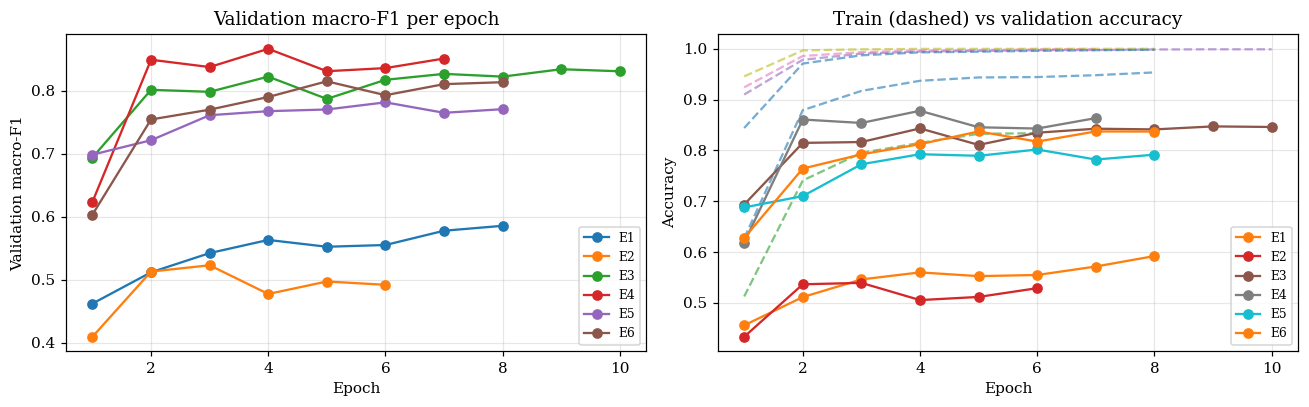

In [7]:
EXPERIMENTS = [
    dict(id='E1', name='Frozen 160px, no aug (M1 setup)', size=160, mode='frozen', aug=False, epochs=8, lr=1e-3, ls=0.0, wd=0.0, init=None, patience=3),
    dict(id='E2', name='Frozen 224px + aug', size=224, mode='frozen', aug=True, epochs=8, lr=1e-3, ls=0.1, wd=0.0, init=None, patience=3),
    dict(id='E3', name='Partial FT (block 13+) 224px + aug', size=224, mode='partial', aug=True, epochs=10, lr=1e-4, ls=0.1, wd=1e-4, init='E2', patience=3),
    dict(id='E4', name='Deeper FT (block 6+) 224px + aug', size=224, mode='deep', aug=True, epochs=10, lr=1e-4, ls=0.1, wd=1e-4, init='E2', patience=3),
    dict(id='E5', name='Partial FT 224px, no aug', size=224, mode='partial', aug=False, epochs=8, lr=1e-4, ls=0.1, wd=1e-4, init='E2', patience=3),
    dict(id='E6', name='Deeper FT 160px + aug', size=160, mode='deep', aug=True, epochs=10, lr=1e-4, ls=0.1, wd=1e-4, init='E1', patience=3),
]
if QUICK:
    for e in EXPERIMENTS:
        e['epochs'] = 1 if e['mode'] == 'frozen' else 2
RUN_EXPERIMENTS = [e['id'] for e in EXPERIMENTS]          # e.g. ['E1','E2','E3'] if GPU time is short
y_val = val_df.label.to_numpy()
VAL_DS = {}

def val_ds_for(size):
    if size not in VAL_DS:
        VAL_DS[size] = make_ds(val_df, size, training=False, one_hot=False)
    return VAL_DS[size]

def run_experiment(e):
    tag = e['id']
    paths = {'ckpt': MODELS / f'{tag}_best.keras', 'probs': PREDS / f'{tag}_val_probs.npy',
             'hist': TABLES / f'{tag}_history.csv', 'meta': TABLES / f'{tag}_result.json'}
    if paths['meta'].exists() and paths['ckpt'].exists():
        print(f'{tag}: already complete — loading results'); return load_json(paths['meta'])
    tf.keras.backend.clear_session(); gc.collect(); seed_everything()
    model, base = build_model(e['size'], e['aug'], dropout=0.3)
    if e['init']:
        src = tf.keras.models.load_model(MODELS / f"{e['init']}_best.keras")
        model.get_layer('head').set_weights(src.get_layer('head').get_weights())
        del src
    set_trainable(base, e['mode'])
    train_ds = make_ds(train_df, e['size'], training=True, one_hot=True)
    steps = e['epochs'] * len(train_ds)
    if e['mode'] == 'frozen':
        opt = tf.keras.optimizers.Adam(e['lr'])
    else:
        warm = max(1, len(train_ds) // 2)
        sched = tf.keras.optimizers.schedules.CosineDecay(initial_learning_rate=e['lr'] / 10, decay_steps=steps - warm,
                                                          alpha=0.02, warmup_target=e['lr'], warmup_steps=warm)
        opt = tf.keras.optimizers.AdamW(learning_rate=sched, weight_decay=e['wd'])
    model.compile(optimizer=opt, loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=e['ls']),
                  metrics=['accuracy'])
    trainable, total = count_params(model)
    print(f"\n=== {tag}: {e['name']} | trainable params {trainable:,} / {total:,} ===")
    cb = ValMacroF1Checkpoint(val_ds_for(e['size']), y_val, paths['ckpt'], paths['probs'], paths['hist'], e['patience'])
    t = time.perf_counter()
    model.fit(train_ds, epochs=e['epochs'], callbacks=[cb], verbose=0)
    train_s = time.perf_counter() - t
    hist = pd.DataFrame(cb.rows); best = hist.loc[hist.val_macro_f1.idxmax()]
    res = {**{k: v for k, v in e.items()}, 'trainable_params': trainable, 'total_params': total,
           'epochs_run': len(hist), 'best_epoch': int(best.epoch), 'val_accuracy': float(best.val_accuracy),
           'val_macro_f1': float(best.val_macro_f1), 'val_loss': float(best.val_loss),
           'train_accuracy_at_best': float(best.train_accuracy), 'training_seconds': train_s,
           'model_mb': round(paths['ckpt'].stat().st_size / 1024 ** 2, 2)}
    save_json(res, paths['meta'])
    del model, base, train_ds; tf.keras.backend.clear_session(); gc.collect()
    print(f"{tag} best: epoch {res['best_epoch']} | val acc {res['val_accuracy']:.4f} | val macro-F1 {res['val_macro_f1']:.4f} | {train_s:.0f}s")
    return res

cnn_results = []
for e in EXPERIMENTS:
    if e['id'] in RUN_EXPERIMENTS:
        if e['init'] and not (MODELS / f"{e['init']}_best.keras").exists():
            print(f"skip {e['id']}: initialiser {e['init']} not available"); continue
        cnn_results.append(run_experiment(e))
cnn_table = pd.DataFrame(cnn_results)
cnn_table.to_csv(TABLES / 'cnn_experiments.csv', index=False)
display(cnn_table[['id', 'name', 'size', 'mode', 'aug', 'trainable_params', 'epochs_run', 'best_epoch',
                   'val_accuracy', 'val_macro_f1', 'training_seconds']])

# Learning curves
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for e in cnn_results:
    h = pd.read_csv(TABLES / f"{e['id']}_history.csv")
    axes[0].plot(h.epoch, h.val_macro_f1, marker='o', label=e['id'])
    axes[1].plot(h.epoch, h.train_accuracy, ls='--', alpha=.6); axes[1].plot(h.epoch, h.val_accuracy, marker='o', label=e['id'])
axes[0].set(xlabel='Epoch', ylabel='Validation macro-F1', title='Validation macro-F1 per epoch')
axes[1].set(xlabel='Epoch', ylabel='Accuracy', title='Train (dashed) vs validation accuracy')
for a_ in axes: a_.grid(alpha=.3); a_.legend(fontsize=8)
savefig(fig, 'cnn_learning_curves.png')

## 8. Validation comparison and model selection (decided before any test evaluation)
The final CNN is the experiment with the highest validation macro-F1. We also fix, *before* testing, which models
will be reported on the test drivers: the selected SVM, the best frozen CNN and the selected (fine-tuned) CNN.

{
 "svm": {
  "hog": "hog128_c16",
  "hog_dims": 1764,
  "model": "LinearSVC",
  "k": 1764,
  "C": 0.01,
  "val_accuracy": 0.4124788255223038,
  "val_macro_f1": 0.4166714647573129,
  "fit_seconds": 81.74369484599993
 },
 "cnn_selected": "E4",
 "cnn_best_frozen": "E1",
 "cnn_best_finetuned": "E4",
 "criterion": "validation macro-F1",
 "decided_at": "2026-11-20 20:37:10"
}


,model,val_accuracy,val_macro_f1
0,"HOG + LinearSVC (hog128_c16, k=1764, C=0.01)",0.412479,0.416671
1,"E1 Frozen 160px, no aug (M1 setup)",0.592038,0.585314
2,E2 Frozen 224px + aug,0.539243,0.522719
3,E3 Partial FT (block 13+) 224px + aug,0.847261,0.833756
4,E4 Deeper FT (block 6+) 224px + aug,0.878035,0.866145
5,"E5 Partial FT 224px, no aug",0.801807,0.781206
6,E6 Deeper FT 160px + aug,0.837380,0.814602


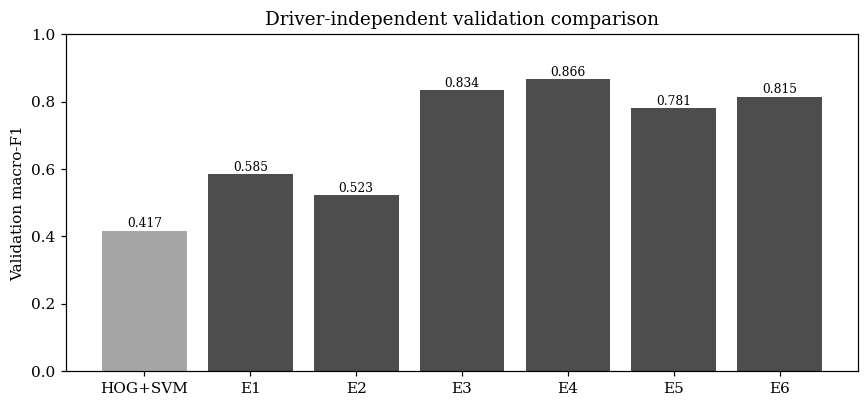

In [8]:
cnn_table = cnn_table.sort_values('val_macro_f1', ascending=False).reset_index(drop=True)
CNN_SEL = cnn_table.iloc[0].to_dict()
FROZEN_SEL = cnn_table[cnn_table['mode'] == 'frozen'].iloc[0].to_dict()
FT_rows = cnn_table[cnn_table['mode'] != 'frozen']
FT_SEL = FT_rows.iloc[0].to_dict() if len(FT_rows) else None
selection = {'svm': SVM_SEL, 'cnn_selected': CNN_SEL['id'], 'cnn_best_frozen': FROZEN_SEL['id'],
             'cnn_best_finetuned': FT_SEL['id'] if FT_SEL else None, 'criterion': 'validation macro-F1',
             'decided_at': time.strftime('%Y-%m-%d %H:%M:%S')}
save_json(selection, OUT / 'model_selection.json')
print(json.dumps(selection, indent=1, default=str))

val_cmp = pd.DataFrame([{'model': f"HOG + {SVM_SEL['model']} ({SVM_SEL['hog']}, k={SVM_SEL['k']}, C={SVM_SEL['C']})",
                         'val_accuracy': SVM_SEL['val_accuracy'], 'val_macro_f1': SVM_SEL['val_macro_f1']}] +
                       [{'model': f"{r['id']} {r['name']}", 'val_accuracy': r['val_accuracy'], 'val_macro_f1': r['val_macro_f1']}
                        for r in cnn_results])
val_cmp.to_csv(TABLES / 'validation_model_comparison.csv', index=False); display(val_cmp)
fig, ax = plt.subplots(figsize=(8, 3.8))
lbl = ['HOG+SVM'] + [r['id'] for r in cnn_results]
ax.bar(lbl, val_cmp.val_macro_f1, color=['0.65'] + ['0.3'] * len(cnn_results))
for i, v in enumerate(val_cmp.val_macro_f1): ax.text(i, v + .01, f'{v:.3f}', ha='center', fontsize=8)
ax.set(ylim=(0, 1), ylabel='Validation macro-F1', title='Driver-independent validation comparison')
savefig(fig, 'validation_comparison.png')

## 9. Validation failure analysis (selected CNN vs. selected SVM)
Per-class precision/recall/F1, row-normalised confusion matrices, most frequent confusions, per-driver accuracy and
the most confident CNN errors. Test labels are not touched.

,class,activity,precision,recall,f1,support,svm_f1
0,c0,Safe driving,0.766,0.950,0.848,397,0.338
1,c1,Texting – right,0.898,0.839,0.868,379,0.369
2,c2,Phone – right,0.986,0.966,0.976,378,0.121
3,c3,Texting – left,0.975,0.930,0.952,373,0.446
4,c4,Phone – left,0.902,0.945,0.923,381,0.014
5,c5,Operating radio,0.887,0.989,0.935,380,0.753
6,c6,Drinking,0.837,0.884,0.860,361,0.558
7,c7,Reaching behind,0.917,0.955,0.936,314,0.826
8,c8,Hair / makeup,0.781,0.654,0.712,295,0.469
9,c9,Talking to passenger,0.807,0.546,0.651,284,0.274


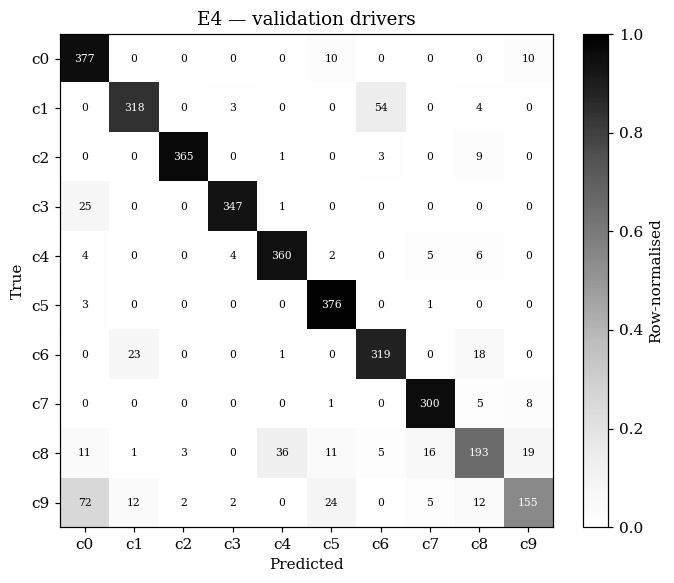

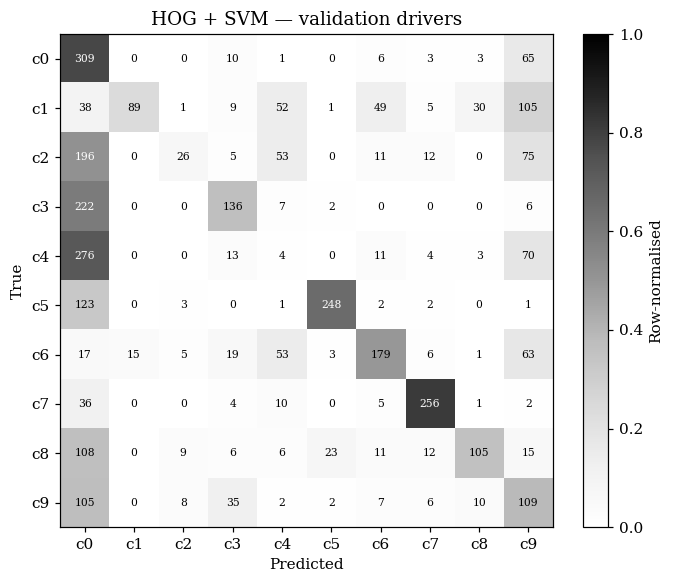

,true,predicted,count,share_of_true_class
0,c9,c0,72,0.253521
1,c1,c6,54,0.142480
2,c8,c4,36,0.122034
3,c3,c0,25,0.067024
4,c9,c5,24,0.084507
5,c6,c1,23,0.063712
6,c8,c9,19,0.064407
7,c6,c8,18,0.049861


,cnn_correct,svm_correct
subject,,
p012,0.844,0.450
p014,0.921,0.349
p061,0.883,0.548
p066,0.865,0.331


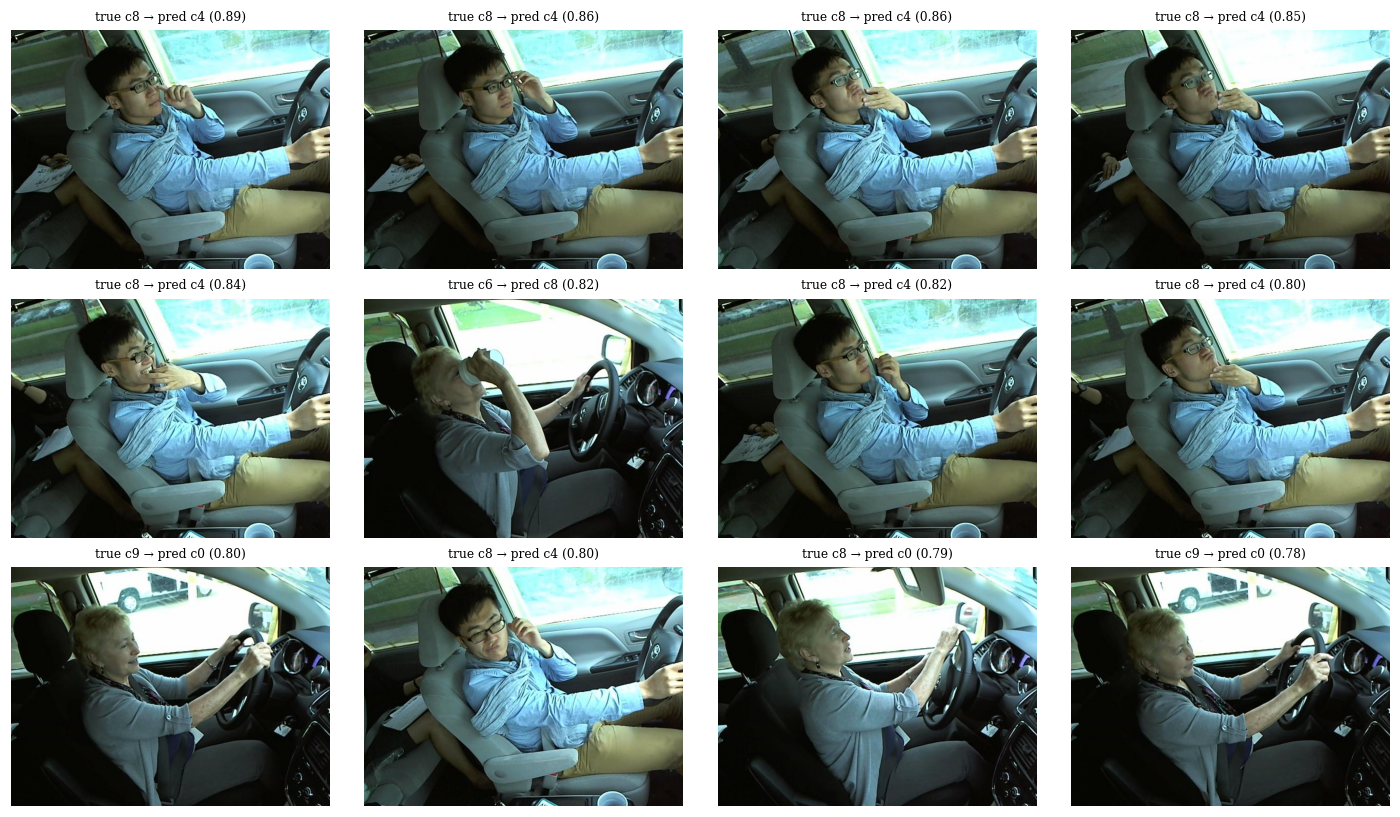

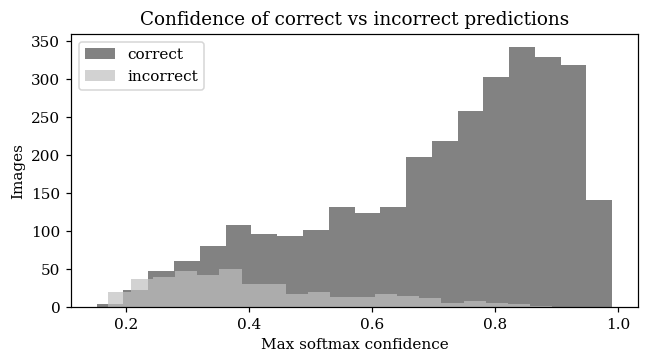

In [9]:
p_val = np.load(PREDS / f"{CNN_SEL['id']}_val_probs.npy"); cnn_val_pred = p_val.argmax(1)

def per_class_table(y, pred):
    p, r, f, s = precision_recall_fscore_support(y, pred, labels=range(N_CLASSES), zero_division=0)
    return pd.DataFrame({'class': CLASS_NAMES, 'activity': [CLASS_LABELS[c] for c in CLASS_NAMES],
                         'precision': p, 'recall': r, 'f1': f, 'support': s})

def plot_cm(y, pred, title, name):
    cm = confusion_matrix(y, pred, labels=range(N_CLASSES))
    cmn = cm / cm.sum(1, keepdims=True).clip(min=1)
    fig, ax = plt.subplots(figsize=(6.4, 5.4))
    im = ax.imshow(cmn, cmap='Greys', vmin=0, vmax=1)
    for i in range(N_CLASSES):
        for j in range(N_CLASSES):
            ax.text(j, i, f'{cm[i, j]}', ha='center', va='center', fontsize=7, color='white' if cmn[i, j] > .5 else 'black')
    ax.set(xticks=range(N_CLASSES), yticks=range(N_CLASSES), xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
           xlabel='Predicted', ylabel='True', title=title)
    fig.colorbar(im, ax=ax, fraction=.046, label='Row-normalised'); savefig(fig, name)
    return cm

def top_confusions(cm, n=8):
    rows = [(CLASS_NAMES[i], CLASS_NAMES[j], int(cm[i, j]), cm[i, j] / cm[i].sum())
            for i in range(N_CLASSES) for j in range(N_CLASSES) if i != j and cm[i, j] > 0]
    return pd.DataFrame(sorted(rows, key=lambda r: -r[2])[:n], columns=['true', 'predicted', 'count', 'share_of_true_class'])

val_pc = per_class_table(y_val, cnn_val_pred).merge(per_class_table(y_val_np, svm_val_pred)[['class', 'f1']].rename(columns={'f1': 'svm_f1'}), on='class')
val_pc.to_csv(TABLES / 'validation_per_class.csv', index=False); display(val_pc.round(3))
cm_cnn_val = plot_cm(y_val, cnn_val_pred, f"{CNN_SEL['id']} — validation drivers", 'cnn_validation_confusion.png')
cm_svm_val = plot_cm(y_val_np, svm_val_pred, 'HOG + SVM — validation drivers', 'svm_validation_confusion.png')
conf_val = top_confusions(cm_cnn_val); conf_val.to_csv(TABLES / 'validation_top_confusions_cnn.csv', index=False); display(conf_val)

drv = val_df.assign(cnn_correct=(cnn_val_pred == y_val), svm_correct=(svm_val_pred == y_val_np)).groupby('subject')[['cnn_correct', 'svm_correct']].mean()
drv.to_csv(TABLES / 'validation_per_driver_accuracy.csv'); display(drv.round(3))

errs = val_df.assign(pred=cnn_val_pred, conf=p_val.max(1))[cnn_val_pred != y_val].sort_values('conf', ascending=False)
errs[['subject', 'classname', 'img', 'pred', 'conf']].assign(pred=lambda d: [CLASS_NAMES[i] for i in d.pred]).to_csv(TABLES / 'validation_errors_cnn.csv', index=False)
fig, axes = plt.subplots(3, 4, figsize=(13, 7.5))
for ax, (_, r) in zip(axes.ravel(), errs.head(12).iterrows()):
    ax.imshow(cv2.cvtColor(cv2.imread(r.filepath), cv2.COLOR_BGR2RGB)); ax.axis('off')
    ax.set_title(f"true {r.classname} → pred {CLASS_NAMES[r.pred]} ({r.conf:.2f})", fontsize=8)
for ax in axes.ravel()[len(errs.head(12)):]: ax.axis('off')
savefig(fig, 'cnn_most_confident_validation_errors.png')

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.hist(p_val.max(1)[cnn_val_pred == y_val], bins=20, alpha=.7, label='correct', color='0.3')
ax.hist(p_val.max(1)[cnn_val_pred != y_val], bins=20, alpha=.7, label='incorrect', color='0.75')
ax.set(xlabel='Max softmax confidence', ylabel='Images', title='Confidence of correct vs incorrect predictions'); ax.legend()
savefig(fig, 'cnn_validation_confidence_hist.png')

## 10. Confidence calibration (validation)
Expected calibration error (ECE, 15 equal-width bins) and temperature scaling. To avoid optimistic estimates the
temperature is **cross-fitted across validation drivers** (fit on two drivers, evaluate on the other two, and swap).
The temperature applied to the test set is then fitted on all validation drivers (never on test).

{
 "model": "E4",
 "val_ece_uncalibrated": 0.20274287635983215,
 "val_ece_temperature_crossfit": 0.020576477067609185,
 "val_nll_uncalibrated": 0.5868828325283822,
 "val_nll_temperature_crossfit": 0.4149254673276702,
 "temperature_folds": [
  0.5541256353117336,
  0.48521651417652434
 ],
 "temperature_all_validation": 0.5212487895156793,
 "mean_confidence": 0.6752921342849731,
 "val_accuracy": 0.8780350084697911
}


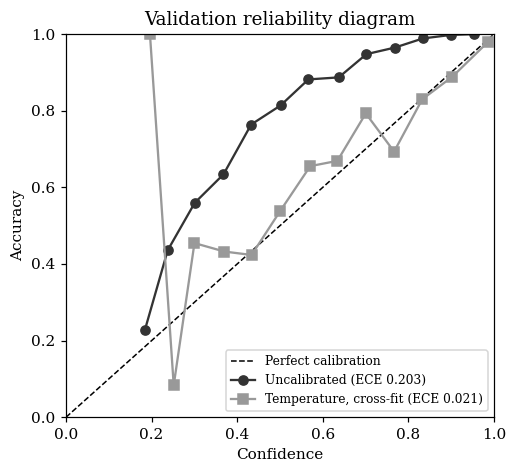

In [10]:
def ece_score(probs, y, bins=15):
    conf, pred = probs.max(1), probs.argmax(1); correct = (pred == y).astype(float)
    edges = np.linspace(0, 1, bins + 1); e = 0.0; rows = []
    for i in range(bins):
        m = (conf > edges[i]) & (conf <= edges[i + 1])
        if m.any():
            e += m.mean() * abs(correct[m].mean() - conf[m].mean())
            rows.append({'bin': i + 1, 'lo': edges[i], 'hi': edges[i + 1], 'count': int(m.sum()),
                         'confidence': conf[m].mean(), 'accuracy': correct[m].mean()})
    return float(e), pd.DataFrame(rows)

def apply_temperature(probs, T):
    z = np.log(np.clip(probs, 1e-7, 1)) / T
    z -= z.max(1, keepdims=True); ez = np.exp(z); return ez / ez.sum(1, keepdims=True)

def fit_temperature(probs, y):
    return float(minimize_scalar(lambda T: safe_log_loss(y, apply_temperature(probs, T)), bounds=(0.25, 10), method='bounded').x)

vd = sorted(val_df.subject.unique()); half = len(vd) // 2
groups = [np.isin(val_df.subject, vd[:half]), np.isin(val_df.subject, vd[half:])]
p_cross = np.zeros_like(p_val); T_folds = []
for fit_m, ev_m in [(groups[0], groups[1]), (groups[1], groups[0])]:
    T_ = fit_temperature(p_val[fit_m], y_val[fit_m]); T_folds.append(T_)
    p_cross[ev_m] = apply_temperature(p_val[ev_m], T_)
T_val = fit_temperature(p_val, y_val)
ece_raw, rel_raw = ece_score(p_val, y_val); ece_cal, rel_cal = ece_score(p_cross, y_val)
calib = {'model': CNN_SEL['id'], 'val_ece_uncalibrated': ece_raw, 'val_ece_temperature_crossfit': ece_cal,
         'val_nll_uncalibrated': safe_log_loss(y_val, p_val), 'val_nll_temperature_crossfit': safe_log_loss(y_val, p_cross),
         'temperature_folds': T_folds, 'temperature_all_validation': T_val,
         'mean_confidence': float(p_val.max(1).mean()), 'val_accuracy': float((cnn_val_pred == y_val).mean())}
save_json(calib, OUT / 'calibration_validation.json'); print(json.dumps(calib, indent=1))
fig, ax = plt.subplots(figsize=(4.8, 4.4))
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Perfect calibration')
ax.plot(rel_raw.confidence, rel_raw.accuracy, 'o-', color='0.2', label=f'Uncalibrated (ECE {ece_raw:.3f})')
ax.plot(rel_cal.confidence, rel_cal.accuracy, 's-', color='0.6', label=f'Temperature, cross-fit (ECE {ece_cal:.3f})')
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel='Confidence', ylabel='Accuracy', title='Validation reliability diagram'); ax.legend(fontsize=8)
savefig(fig, 'reliability_diagram_validation.png')

## 11. Controlled robustness: brightness and blur (validation subset)
A stratified 600-image validation subset is perturbed **at full resolution**, then passed through each pipeline's own
preprocessing (HOG for the SVM; resize + in-model normalisation for the CNN). These are simulated shifts only; they are
not evidence of real-road robustness.

/tmp/ipykernel_24/1584271090.py:2: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  rob = val_df.groupby('classname', group_keys=False).apply(lambda g: g.sample(n=min(len(g), ROB_N // 10), random_state=SEED)).reset_index(drop=True)


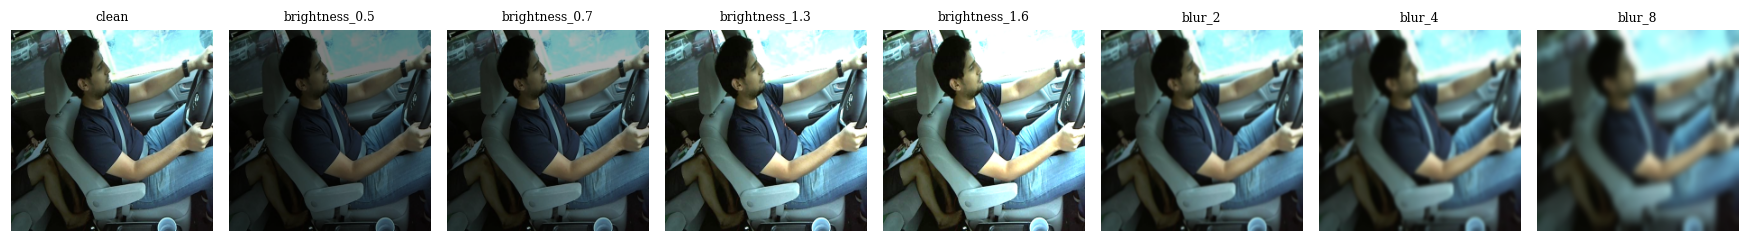

model,E4,HOG+SVM
perturbation,,
clean,0.852,0.428
brightness_0.5,0.780,0.421
brightness_0.7,0.836,0.425
brightness_1.3,0.859,0.415
brightness_1.6,0.852,0.425
blur_2,0.818,0.434
blur_4,0.775,0.395
blur_8,0.393,0.290


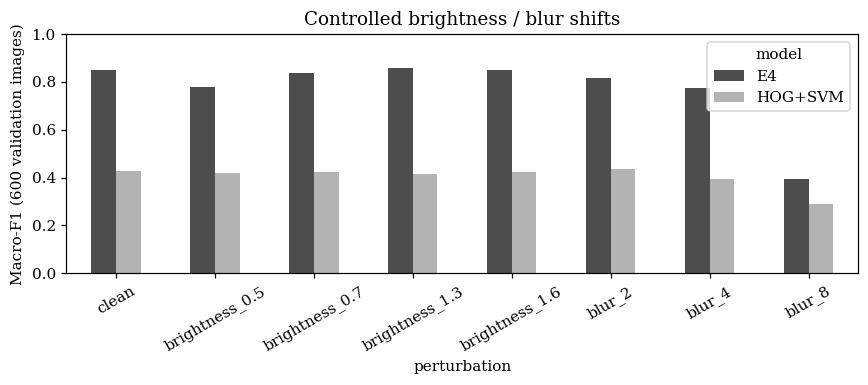

In [11]:
ROB_N = 60 if QUICK else 600
rob = val_df.groupby('classname', group_keys=False).apply(lambda g: g.sample(n=min(len(g), ROB_N // 10), random_state=SEED)).reset_index(drop=True)
PERTURB = ['clean', 'brightness_0.5', 'brightness_0.7', 'brightness_1.3', 'brightness_1.6', 'blur_2', 'blur_4', 'blur_8']
rob_path = TABLES / 'robustness_validation.csv'
if rob_path.exists():
    rob_df = pd.read_csv(rob_path); print('Loaded robustness results')
else:
    cnn_sel_model = tf.keras.models.load_model(MODELS / f"{CNN_SEL['id']}_best.keras")
    size = int(CNN_SEL['size']); svm_cfg = {SVM_SEL['hog']: HOG_CONFIGS[SVM_SEL['hog']]}
    rows = []; examples = {}
    for kind in PERTURB:
        H, X = [], np.zeros((len(rob), size, size, 3), np.uint8)
        for i, pth in enumerate(rob.filepath):
            img = perturb_bgr(cv2.imread(pth), kind)
            H.append(hog_from_bgr(img, svm_cfg)[0])
            X[i] = cv2.resize(cv2.cvtColor(img, cv2.COLOR_BGR2RGB), (size, size), interpolation=cv2.INTER_AREA)
            if i == 0: examples[kind] = X[i].copy()
        ps = svm_best.predict(np.stack(H)); pc = cnn_sel_model.predict(make_image_ds(X), verbose=0).argmax(1)
        yy = rob.label.to_numpy()
        for mdl, pr in [('HOG+SVM', ps), (CNN_SEL['id'], pc)]:
            rows.append({'perturbation': kind, 'model': mdl, 'accuracy': accuracy_score(yy, pr),
                         'macro_f1': f1_score(yy, pr, average='macro', zero_division=0)})
        del X, H; gc.collect()
    rob_df = pd.DataFrame(rows); rob_df.to_csv(rob_path, index=False)
    fig, axes = plt.subplots(1, len(PERTURB), figsize=(16, 2.4))
    for ax, k in zip(axes, PERTURB): ax.imshow(examples[k]); ax.set_title(k, fontsize=8); ax.axis('off')
    savefig(fig, 'robustness_examples.png')
    del cnn_sel_model; tf.keras.backend.clear_session(); gc.collect()
piv = rob_df.pivot(index='perturbation', columns='model', values='macro_f1').loc[PERTURB]
display(piv.round(3))
fig, ax = plt.subplots(figsize=(8, 3.6))
piv.plot.bar(ax=ax, color=['0.3', '0.7']); ax.set(ylabel='Macro-F1 (600 validation images)', ylim=(0, 1), title='Controlled brightness / blur shifts')
ax.tick_params(axis='x', rotation=30); savefig(fig, 'robustness_validation.png')

## 12. Computational cost: training time, model size and inference latency
Latency is measured on the same Kaggle session. *Model-only* excludes image decoding; *end-to-end* includes
reading the JPEG and all preprocessing (HOG extraction for the SVM), single image, on CPU (deployment-like) and,
for the CNN, also batched on GPU. MobileNetV2's ImageNet pre-training cost is **not** included in our training time.

In [12]:
def time_it(fn, reps):
    fn()                                               # warm-up
    t = time.perf_counter()
    for _ in range(reps): fn()
    return (time.perf_counter() - t) / reps * 1000

cost_path = TABLES / 'computational_cost.csv'
if cost_path.exists():
    cost = pd.read_csv(cost_path)
else:
    reps = 5 if QUICK else 30
    lat_paths = val_df.filepath.values[:reps]
    size = int(CNN_SEL['size'])
    m = tf.keras.models.load_model(MODELS / f"{CNN_SEL['id']}_best.keras")
    infer = tf.function(lambda x: m(x, training=False))
    with tf.device('/CPU:0'):
        x1 = tf.zeros((1, size, size, 3)); _ = infer(x1)
        cnn_cpu1 = time_it(lambda: infer(x1).numpy(), reps)
        def cnn_e2e():
            for p in lat_paths[:5]: infer(load_rgb(p, size)[None]).numpy()
        cnn_cpu_e2e = time_it(cnn_e2e, 3) / 5
    cnn_gpu_b32 = None
    if GPUS:
        xb = tf.zeros((32, size, size, 3)); _ = infer(xb)
        cnn_gpu_b32 = time_it(lambda: infer(xb).numpy(), reps) / 32
    Hs = np.asarray(H_val[SVM_SEL['hog']][:1])
    svm_model_only = time_it(lambda: svm_best.predict(Hs), reps)
    svm_cfg = {SVM_SEL['hog']: HOG_CONFIGS[SVM_SEL['hog']]}
    def svm_e2e():
        for p in lat_paths[:5]: svm_best.predict(hog_from_bgr(cv2.imread(p), svm_cfg)[0][None])
    svm_cpu_e2e = time_it(svm_e2e, 3) / 5
    tr, tot = count_params(m); del m; tf.keras.backend.clear_session()
    cost = pd.DataFrame([
        {'model': f"HOG + {SVM_SEL['model']}", 'trainable_params': None, 'training_seconds': float(SVM_SEL['fit_seconds']),
         'feature_extraction_seconds_train_val': hog_extraction_seconds, 'model_size_mb': round(svm_model_path.stat().st_size / 1024 ** 2, 2),
         'cpu_ms_per_image_model_only': svm_model_only, 'cpu_ms_per_image_end_to_end': svm_cpu_e2e, 'gpu_ms_per_image_batch32': None},
        {'model': f"MobileNetV2 {CNN_SEL['id']}", 'trainable_params': tr,
         'training_seconds': float(CNN_SEL['training_seconds']) + (float(cnn_table.set_index('id').loc[CNN_SEL['init'], 'training_seconds']) if isinstance(CNN_SEL.get('init'), str) and CNN_SEL['init'] in set(cnn_table.id) else 0.0),
         'feature_extraction_seconds_train_val': None, 'model_size_mb': float(CNN_SEL['model_mb']),
         'cpu_ms_per_image_model_only': cnn_cpu1, 'cpu_ms_per_image_end_to_end': cnn_cpu_e2e, 'gpu_ms_per_image_batch32': cnn_gpu_b32}])
    cost.to_csv(cost_path, index=False)
display(cost)
cnn_table[['id', 'name', 'trainable_params', 'total_params', 'epochs_run', 'training_seconds', 'model_mb', 'val_macro_f1']].to_csv(TABLES / 'cnn_cost_by_experiment.csv', index=False)

,model,trainable_params,training_seconds,feature_extraction_seconds_train_val,model_size_mb,cpu_ms_per_image_model_only,cpu_ms_per_image_end_to_end,gpu_ms_per_image_batch32
0,HOG + LinearSVC,NaN,81.743695,175.615877,0.19,0.525067,7.192278,NaN
1,MobileNetV2 E4,2150602.0,584.708147,NaN,25.67,33.397911,38.984508,1.483193


## 13. One-time evaluation on the untouched held-out test drivers
Runs **once**: results and a lock file (`TEST_EVALUATED.json`, containing the model-selection record) are written
to `/kaggle/working`. On any later run the stored results are loaded instead of re-evaluating, so the test set
cannot be used for tuning. The pre-declared models are the selected SVM, the best frozen CNN and the selected CNN.
HOG features for the test drivers are extracted here in resumable chunks (the step that crashed previously).

HOG test:   0%|          | 0/3 [00:00<?, ?it/s]

HOG test: 4978 images in 52.8s
Held-out test evaluated and locked.


,model,accuracy,macro_f1,macro_precision,macro_recall,accuracy_95ci,macro_f1_95ci,log_loss,ece,ece_after_val_temperature,log_loss_after_val_temperature
0,HOG + LinearSVC,0.545199,0.534324,0.618448,0.538709,"[0.532342306147047, 0.5594616311771796]","[0.5205714906300694, 0.5477207958418236]",NaN,NaN,NaN,NaN
1,MobileNetV2 E1,0.555042,0.556634,0.596719,0.554023,"[0.5421805946163119, 0.5697067095218964]","[0.5434282970452831, 0.5709048869691672]",1.444619,0.154314,0.289904,2.197232
2,MobileNetV2 E4,0.898755,0.890211,0.906810,0.890576,"[0.8907141422257936, 0.9067898754519887]","[0.881228946511112, 0.8987024361295094]",0.557238,0.226419,0.025133,0.341171


McNemar (selected CNN vs SVM): {'a_right_b_wrong': 1943, 'a_wrong_b_right': 183, 'chi2': 1455.3532455315146, 'p_value': 0.0}


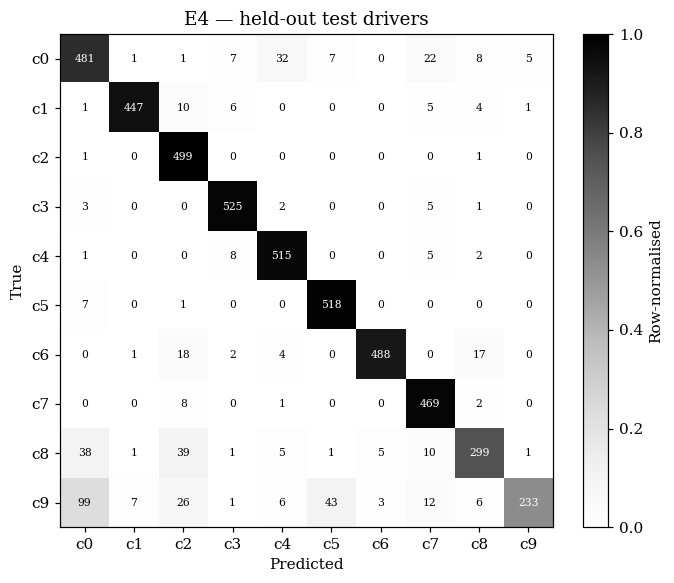

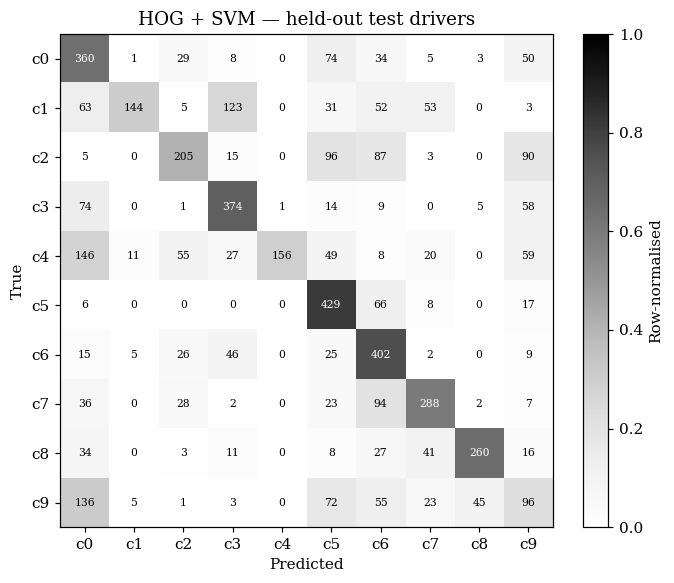

,class,activity,precision,recall,f1,support
0,c0,Safe driving,0.762,0.853,0.805,564
1,c1,Texting – right,0.978,0.943,0.960,474
2,c2,Phone – right,0.829,0.996,0.905,501
3,c3,Texting – left,0.955,0.979,0.967,536
4,c4,Phone – left,0.912,0.970,0.940,531
5,c5,Operating radio,0.910,0.985,0.946,526
6,c6,Drinking,0.984,0.921,0.951,530
7,c7,Reaching behind,0.888,0.977,0.931,480
8,c8,Hair / makeup,0.879,0.748,0.808,400
9,c9,Talking to passenger,0.971,0.534,0.689,436


In [13]:
TEST_LOCK = OUT / 'TEST_EVALUATED.json'
RUN_FINAL_TEST = True

def bootstrap_ci(y, pred, n=1000, seed=SEED):
    r = np.random.default_rng(seed); accs, f1s = [], []
    for _ in range(n):
        i = r.integers(0, len(y), len(y))
        accs.append(accuracy_score(y[i], pred[i])); f1s.append(f1_score(y[i], pred[i], average='macro', zero_division=0))
    return [float(np.percentile(accs, 2.5)), float(np.percentile(accs, 97.5))], [float(np.percentile(f1s, 2.5)), float(np.percentile(f1s, 97.5))]

def mcnemar(y, a, b):
    n01 = int(((a == y) & (b != y)).sum()); n10 = int(((a != y) & (b == y)).sum())
    stat = (abs(n01 - n10) - 1) ** 2 / max(n01 + n10, 1)
    return {'a_right_b_wrong': n01, 'a_wrong_b_right': n10, 'chi2': stat, 'p_value': float(chi2.sf(stat, 1))}

def summarise(name, y, pred, probs=None):
    p, r, f, _ = precision_recall_fscore_support(y, pred, average='macro', zero_division=0)
    ci_a, ci_f = bootstrap_ci(y, pred)
    d = {'model': name, 'accuracy': accuracy_score(y, pred), 'macro_f1': f, 'macro_precision': p, 'macro_recall': r,
         'accuracy_95ci': ci_a, 'macro_f1_95ci': ci_f}
    if probs is not None:
        d.update({'log_loss': safe_log_loss(y, probs), 'ece': ece_score(probs, y)[0],
                  'ece_after_val_temperature': ece_score(apply_temperature(probs, T_val), y)[0],
                  'log_loss_after_val_temperature': safe_log_loss(y, apply_temperature(probs, T_val))})
    return d

if TEST_LOCK.exists():
    test_record = load_json(TEST_LOCK)
    print('Held-out test already evaluated at', test_record['evaluated_at'], '— loading stored results (no re-evaluation).')
elif RUN_FINAL_TEST:
    H_test = extract_hog(test_df, 'test')
    svm_test_pred = batched_predict(svm_best.predict, H_test[SVM_SEL['hog']]); del H_test; gc.collect()
    test_models = {'svm': svm_test_pred}
    probs_test = {}
    for role, eid in [('cnn_best_frozen', FROZEN_SEL['id']), ('cnn_selected', CNN_SEL['id'])]:
        if eid in probs_test: continue
        size = int(cnn_table.set_index('id').loc[eid, 'size'])
        m = tf.keras.models.load_model(MODELS / f'{eid}_best.keras')
        probs_test[eid] = m.predict(make_ds(test_df, size, training=False, one_hot=False), verbose=0)
        np.save(PREDS / f'{eid}_test_probs.npy', probs_test[eid]); del m; tf.keras.backend.clear_session(); gc.collect()
    np.save(PREDS / 'svm_test_pred.npy', svm_test_pred)
    rows = [summarise(f"HOG + {SVM_SEL['model']}", y_test_np, svm_test_pred)]
    for eid in dict.fromkeys([FROZEN_SEL['id'], CNN_SEL['id']]):
        rows.append(summarise(f"MobileNetV2 {eid}", y_test_np, probs_test[eid].argmax(1), probs_test[eid]))
    sel_pred = probs_test[CNN_SEL['id']].argmax(1)
    test_record = {'evaluated_at': time.strftime('%Y-%m-%d %H:%M:%S'), 'selection': selection, 'results': rows,
                   'mcnemar_selected_cnn_vs_svm': mcnemar(y_test_np, sel_pred, svm_test_pred),
                   'per_class_selected_cnn': per_class_table(y_test_np, sel_pred).to_dict('records'),
                   'per_class_svm': per_class_table(y_test_np, svm_test_pred).to_dict('records'),
                   'per_driver_accuracy': test_df.assign(cnn=(sel_pred == y_test_np), svm=(svm_test_pred == y_test_np)).groupby('subject')[['cnn', 'svm']].mean().reset_index().to_dict('records')}
    save_json(test_record, TEST_LOCK)
    print('Held-out test evaluated and locked.')
else:
    test_record = None; print('Final test not run (RUN_FINAL_TEST=False).')

if test_record:
    test_table = pd.DataFrame(test_record['results']); test_table.to_csv(TABLES / 'heldout_test_results.csv', index=False)
    display(test_table)
    print('McNemar (selected CNN vs SVM):', test_record['mcnemar_selected_cnn_vs_svm'])
    sel_pred = np.load(PREDS / f"{CNN_SEL['id']}_test_probs.npy").argmax(1); svm_test_pred = np.load(PREDS / 'svm_test_pred.npy')
    cm_cnn_test = plot_cm(y_test_np, sel_pred, f"{CNN_SEL['id']} — held-out test drivers", 'cnn_test_confusion.png')
    plot_cm(y_test_np, svm_test_pred, 'HOG + SVM — held-out test drivers', 'svm_test_confusion.png')
    top_confusions(cm_cnn_test).to_csv(TABLES / 'test_top_confusions_cnn.csv', index=False)
    pd.DataFrame(test_record['per_class_selected_cnn']).to_csv(TABLES / 'test_per_class_cnn.csv', index=False)
    pd.DataFrame(test_record['per_driver_accuracy']).to_csv(TABLES / 'test_per_driver_accuracy.csv', index=False)
    display(pd.DataFrame(test_record['per_class_selected_cnn']).round(3))

## 14. Results summary and downloadable bundle
Writes `results_summary.json` (read by `make_report.py` to build the final Word/PDF report) and zips all
lightweight outputs (tables, figures, JSON, the selected models) into `driverguard_outputs.zip`.

In [14]:
summary = {'project': 'DriverGuard', 'authors': ['Khaled Sabehayoun', 'Karl Khadij'], 'course': 'CMPS 262',
           'environment': ENV, 'audit': audit, 'splits': split_summary.to_dict('records'),
           'svm_grid': svm_table.to_dict('records'), 'svm_selected': SVM_SEL, 'hog_extraction_seconds_train_val': hog_extraction_seconds,
           'cnn_experiments': cnn_table.to_dict('records'), 'selection': selection,
           'validation_per_class': val_pc.to_dict('records'), 'validation_top_confusions': conf_val.to_dict('records'),
           'validation_per_driver': drv.reset_index().to_dict('records'), 'calibration': calib,
           'robustness': rob_df.to_dict('records'), 'cost': cost.to_dict('records'), 'test': test_record}
save_json(summary, OUT / 'results_summary.json')
bundle = OUT / 'driverguard_outputs.zip'
with zipfile.ZipFile(bundle, 'w', zipfile.ZIP_DEFLATED) as z:
    for sub in [TABLES, FIGS, PREDS]:
        for f in sub.glob('*'): z.write(f, f.relative_to(OUT))
    for f in OUT.glob('*.json'): z.write(f, f.name)
    for f in [svm_model_path, MODELS / f"{CNN_SEL['id']}_best.keras"]:
        if f.exists(): z.write(f, f.relative_to(OUT))
print('Wrote', OUT / 'results_summary.json', 'and', bundle, f'({bundle.stat().st_size / 1024 ** 2:.1f} MB)')

Wrote /kaggle/working/results_summary.json and /kaggle/working/driverguard_outputs.zip (32.1 MB)
